# KernelSynth — séries versus previsões AR

Este notebook compara uma trajetória de teste do KernelSynth com a previsão AR de um passo à frente. Para cada série, escolhe-se a ordem AR com menor NMSE entre as ordens testadas. A divisão é exclusivamente `deu certo` quando `NMSE <= 0.001` e `deu errado` quando `NMSE > 0.001`. O título registra a equação AR, sua ordem, o intercepto e os coeficientes (abreviados quando a ordem é longa).

In [1]:
from __future__ import annotations

from pathlib import Path
import hashlib
import importlib.metadata
import json
import math
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'experiments').exists():
            return candidate
    raise RuntimeError('Repository root not found')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_NOTEBOOK = PROJECT_ROOT / 'experiments' / 'autoregressive_process_coverage' / 'AR' / '01_kernelsynth_ar_coverage.ipynb'
PLOT_POINTS = 320
NMSE_THRESHOLD = 0.001

def notebook_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))

def embedded_record(notebook: dict) -> dict:
    for cell in reversed(notebook['cells']):
        for output in cell.get('outputs', []):
            text = ''.join(output.get('text', []))
            if 'COMPLETE EXPERIMENT RECORD' in text and '{' in text:
                return json.loads(text[text.index('{'):])
    raise RuntimeError('Canonical experiment record not found')

source_nb = notebook_json(SOURCE_NOTEBOOK)
canonical_record = embedded_record(source_nb)
# Reuse the exact configuration, generators, AR implementation, and function bank recorded by the source experiment.
for cell_index in (1, 3):
    source = ''.join(source_nb['cells'][cell_index]['source'])
    exec(compile(source, f'{SOURCE_NOTEBOOK}#cell-{cell_index}', 'exec'), globals())

print(f'Fonte canônica: {SOURCE_NOTEBOOK.relative_to(PROJECT_ROOT)}')
print(f'Funções: {len(FUNCTIONS)} | ordens: {ORDERS}')

,id,category,family,formula
0,periodic_01_p24,base,periodic,"ExpSineSquared(length_scale=1, periodicity=24/..."
1,periodic_02_p48,base,periodic,"ExpSineSquared(length_scale=1, periodicity=48/..."
2,periodic_03_p96,base,periodic,"ExpSineSquared(length_scale=1, periodicity=96/..."
3,periodic_04_p168,base,periodic,"ExpSineSquared(length_scale=1, periodicity=168..."
4,periodic_05_p336,base,periodic,"ExpSineSquared(length_scale=1, periodicity=336..."
5,periodic_06_p672,base,periodic,"ExpSineSquared(length_scale=1, periodicity=672..."
6,periodic_07_p7,base,periodic,"ExpSineSquared(length_scale=1, periodicity=7/1..."
7,periodic_08_p14,base,periodic,"ExpSineSquared(length_scale=1, periodicity=14/..."
8,periodic_09_p30,base,periodic,"ExpSineSquared(length_scale=1, periodicity=30/..."
9,periodic_10_p60,base,periodic,"ExpSineSquared(length_scale=1, periodicity=60/..."


Fonte canônica: experiments\autoregressive_process_coverage\AR\01_kernelsynth_ar_coverage.ipynb
Funções: 53 | ordens: [1, 2, 4, 8, 16, 32, 64, 128, 256]


## Reconstrução determinística e seleção dos modelos

In [2]:
forecast_rows = []
data_by_function = {}
for function_index, function in enumerate(FUNCTIONS):
    factor = stable_factor(function['covariance'])
    local_rng = np.random.default_rng(GLOBAL_SEED + 100_000 + function_index)
    raw_train = draw_from_factor(factor, N_TRAIN, local_rng)
    raw_test = draw_from_factor(factor, N_TEST, local_rng)
    train, test, _, _ = standardize_train_test(raw_train, raw_test)
    data_by_function[function['id']] = (train, test)
    for order in ORDERS:
        fit = fit_ar(train, order)
        _, target = lagged_design(test, order)
        prediction = ar_predictions(fit, test)
        nmse = float(np.mean((target - prediction) ** 2) / (np.var(target) + 1e-12))
        forecast_rows.append({'function': function['id'], 'order': order, 'forecast_nmse': nmse})

forecast_results = pd.DataFrame(forecast_rows)
selected_rows = []
plot_cases = []
for function in FUNCTIONS:
    function_id = function['id']
    candidates = forecast_results[forecast_results['function'].eq(function_id)]
    winner = candidates.sort_values(['forecast_nmse', 'order']).iloc[0]
    order = int(winner['order'])
    evaluation_nmse = float(winner['forecast_nmse'])
    status = evaluation_nmse <= NMSE_THRESHOLD
    selection_rule = 'menor NMSE entre todas as ordens'
    train, test = data_by_function[function_id]
    fit = fit_ar(train, order)
    actual = test[0, order:]
    prediction = ar_predictions(fit, test[:1])
    nmse = float(np.mean((actual - prediction) ** 2) / (np.var(actual) + 1e-12))
    selected_rows.append({'function': function_id, 'covered': status, 'order': order,
                          'selection_rule': selection_rule, 'forecast_nmse': evaluation_nmse,
                          'representative_nmse': nmse})
    plot_cases.append({'function': function_id, 'covered': status, 'order': order, 'fit': fit,
                       'actual': actual, 'prediction': prediction, 'nmse': nmse,
                       'evaluation_nmse': evaluation_nmse})

selected = pd.DataFrame(selected_rows)
display(selected)

,function,covered,order,selection_rule,forecast_nmse,representative_nmse
0,periodic_01_p24,True,256,menor NMSE entre todas as ordens,1.386932e-10,2.554157e-10
1,periodic_02_p48,True,256,menor NMSE entre todas as ordens,1.355517e-10,1.504421e-10
2,periodic_03_p96,True,256,menor NMSE entre todas as ordens,1.108262e-10,6.110286e-11
3,periodic_04_p168,True,256,menor NMSE entre todas as ordens,1.719299e-10,1.115092e-08
4,periodic_05_p336,True,256,menor NMSE entre todas as ordens,2.390799e-10,8.899164e-10
5,periodic_06_p672,True,128,menor NMSE entre todas as ordens,2.498210e-10,4.704799e-10
6,periodic_07_p7,True,256,menor NMSE entre todas as ordens,1.479141e-10,9.498268e-10
7,periodic_08_p14,True,256,menor NMSE entre todas as ordens,1.083712e-10,3.678999e-10
8,periodic_09_p30,True,256,menor NMSE entre todas as ordens,1.245083e-10,1.901026e-10
9,periodic_10_p60,True,256,menor NMSE entre todas as ordens,1.443962e-10,7.863568e-10


In [3]:
def coefficient_preview(coefficients: np.ndarray, shown: int = 6) -> str:
    values = [f'{value:+.3g}' for value in coefficients]
    if len(values) <= shown + 2:
        return '[' + ', '.join(values) + ']'
    return '[' + ', '.join(values[:shown]) + ', ..., ' + ', '.join(values[-2:]) + ']'

def ar_equation(fit) -> str:
    p = len(fit.coefficients)
    return (f'ŷ[t] = {fit.intercept:.3g} + Σ(k=1..{p}) φ[k]·y[t-k]  '
            f'|  φ={coefficient_preview(fit.coefficients)}')

def plot_cases_in_one_figure(cases: list[dict], heading: str) -> None:
    if not cases:
        print(f'{heading}: nenhum caso')
        return
    columns = 3
    rows = math.ceil(len(cases) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(20, 3.8 * rows), squeeze=False)
    for ax, case in zip(axes.flat, cases):
        points = min(PLOT_POINTS, len(case['actual']))
        x = np.arange(case['order'], case['order'] + points)
        ax.plot(x, case['actual'][:points], color='#4C78A8', linewidth=1.2, label='KernelSynth')
        ax.plot(x, case['prediction'][:points], color='#E45756', linewidth=1.0, alpha=0.9, label='AR')
        ax.set_title(f"{case['function']} | AR({case['order']})\n{ar_equation(case['fit'])}", fontsize=8)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7, loc='upper right')
    for ax in axes.flat[len(cases):]:
        ax.remove()
    fig.suptitle(heading, fontsize=16, y=1.002)
    fig.tight_layout()
    plt.show()

## Critério de divisão

Para cada série, o notebook escolhe a ordem AR com menor NMSE no conjunto de teste. A série **deu certo** quando esse menor NMSE é `<= 0.001` e **deu errado** quando é `> 0.001`. Os valores individuais de `forecast_nmse` estão na tabela acima; os gráficos mostram somente as curvas e a equação AR para evitar repetição visual.

## Todos os casos que deram certo por NMSE — uma célula

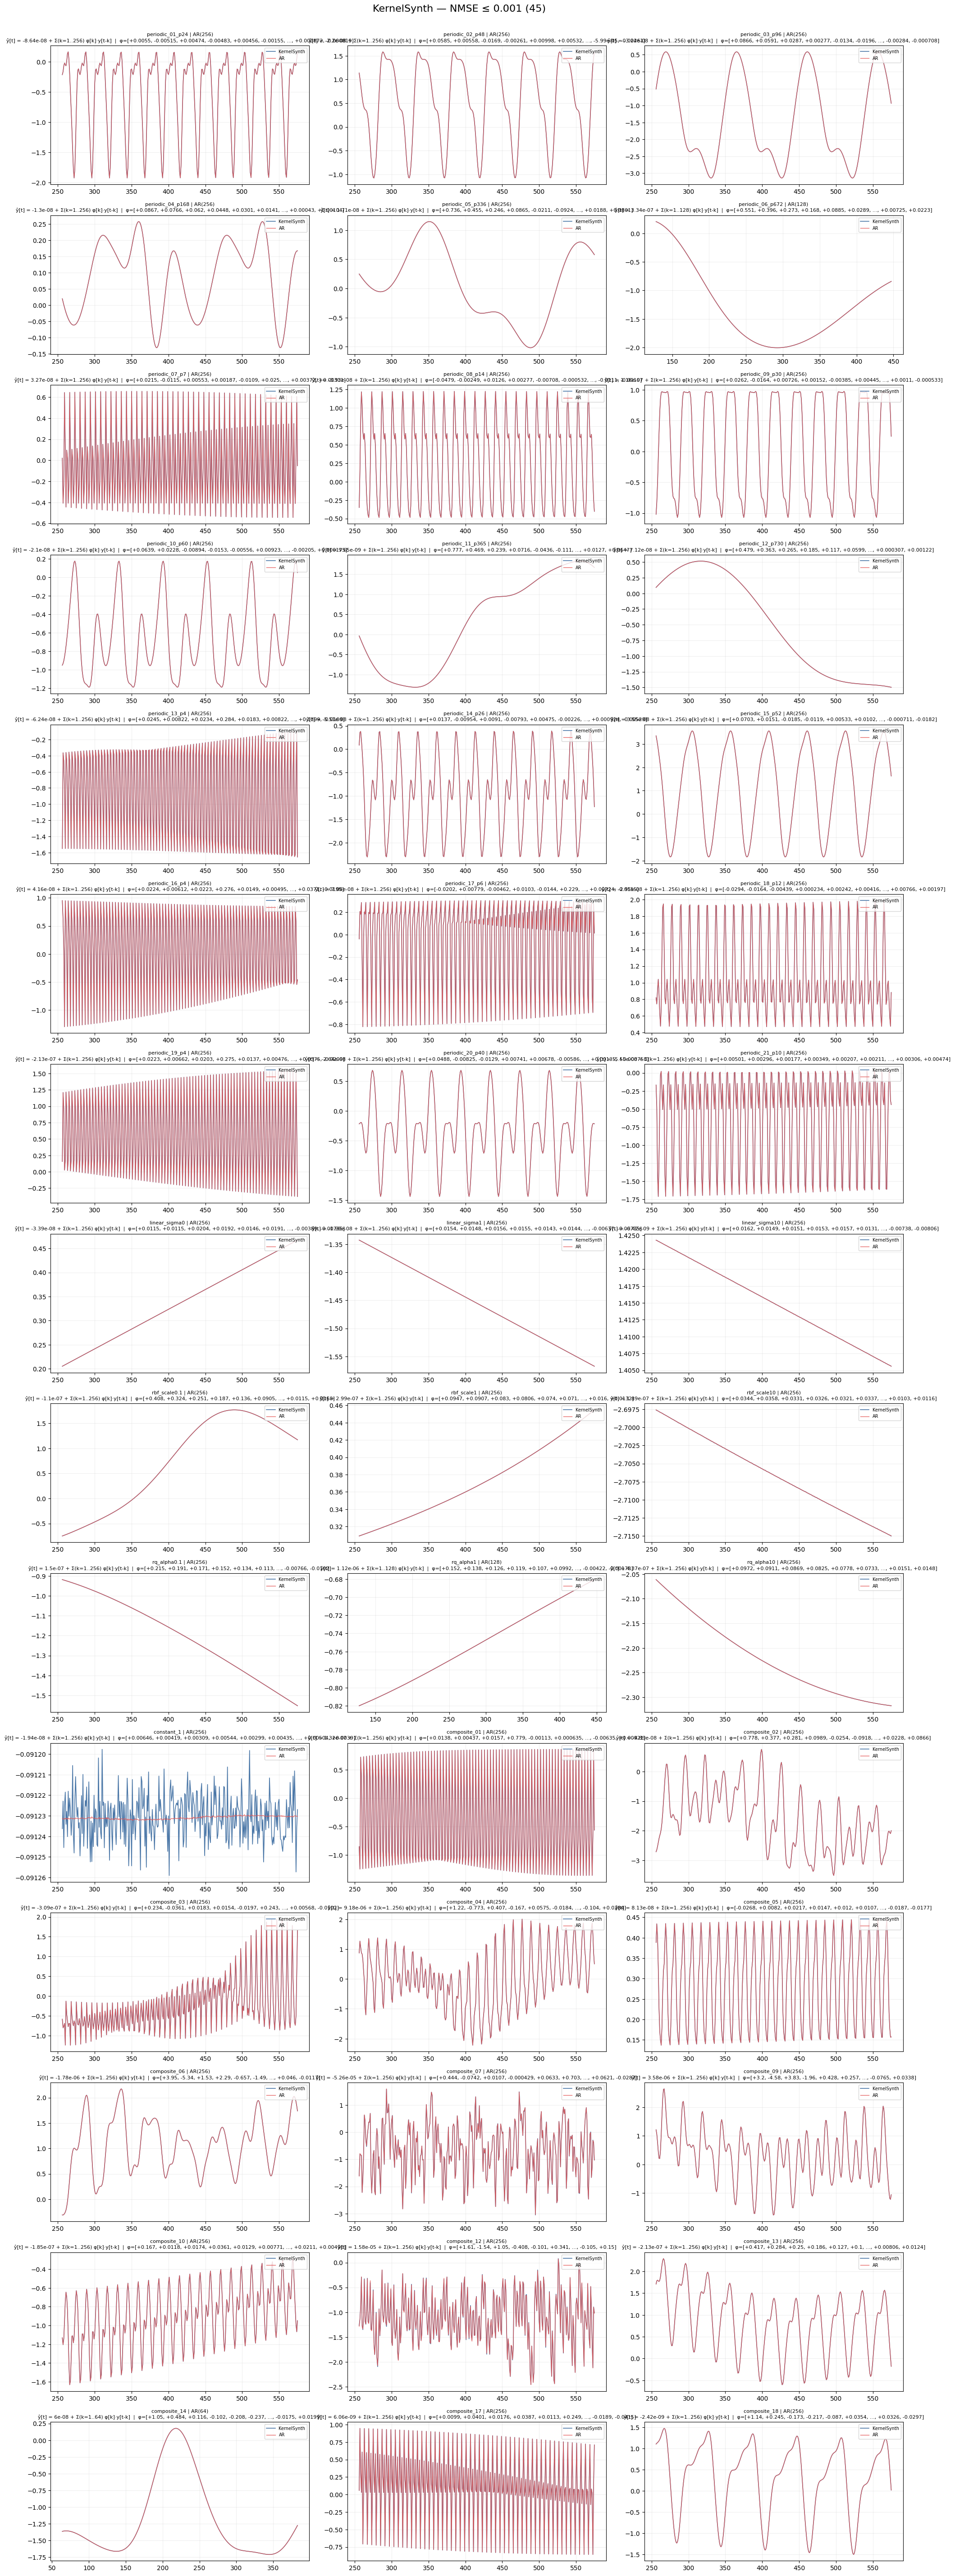

In [4]:
successful_cases = [case for case in plot_cases if case['covered']]
plot_cases_in_one_figure(successful_cases, f'KernelSynth — NMSE ≤ {NMSE_THRESHOLD:g} ({len(successful_cases)})')

## Todos os casos que não deram certo por NMSE — uma célula

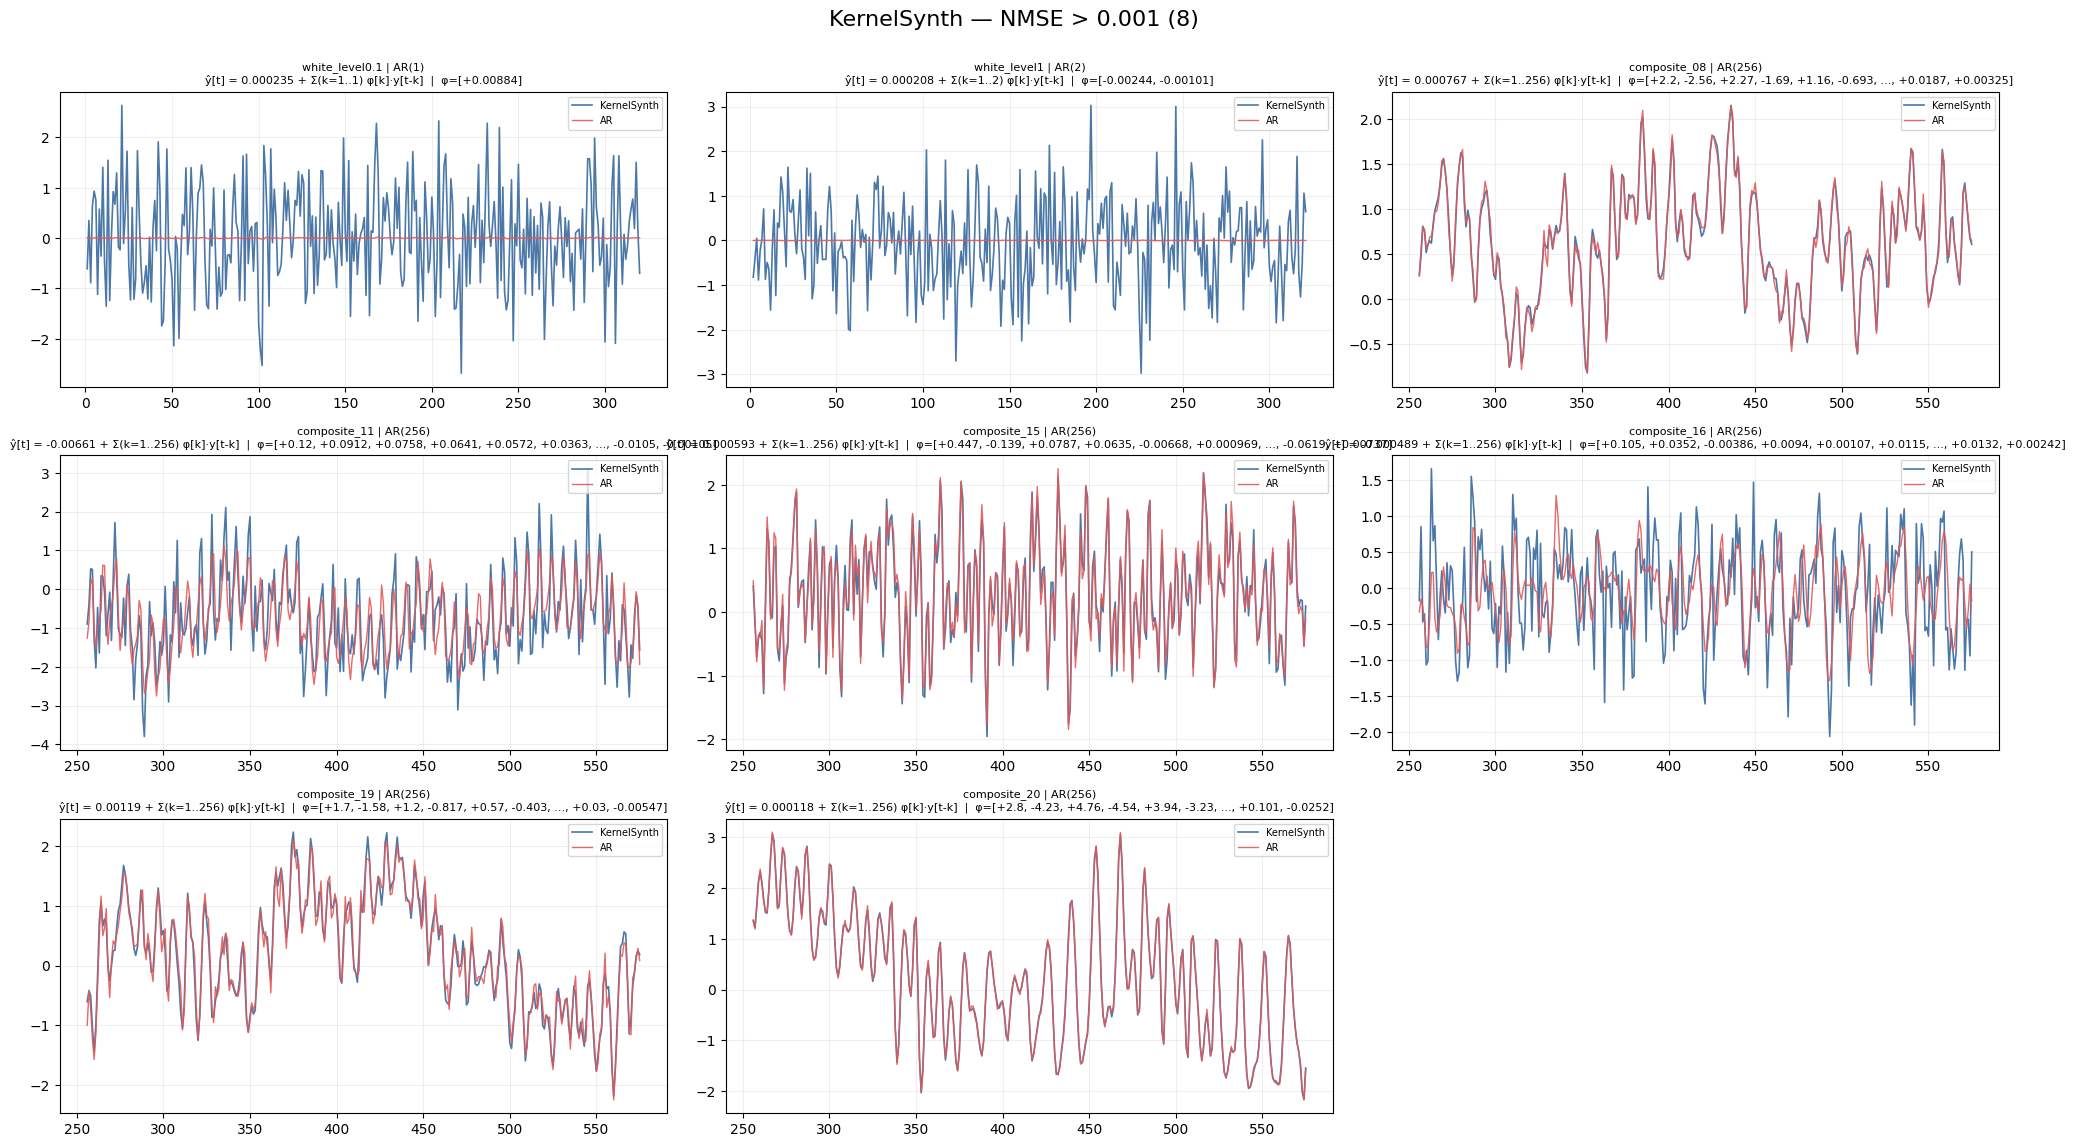

In [5]:
failed_cases = [case for case in plot_cases if not case['covered']]
plot_cases_in_one_figure(failed_cases, f'KernelSynth — NMSE > {NMSE_THRESHOLD:g} ({len(failed_cases)})')

## COMPLETE EXPERIMENT RECORD — registro canônico deste notebook

In [6]:
record = {
    'experiment_id': 'kernelsynth_ar_prediction_results',
    'status': 'executed',
    'research_question': 'How do representative KernelSynth test trajectories compare visually with their selected one-step AR predictions?',
    'hypothesis': 'The minimum-NMSE AR model separates visually accurate and inaccurate one-step forecasts at an NMSE threshold of 0.001.',
    'configuration': {
        'source_experiment': str(SOURCE_NOTEBOOK.relative_to(PROJECT_ROOT)),
        'plot_points': PLOT_POINTS,
        'model_selection': 'minimum forecast_nmse across all canonical AR orders for every series',
        'success_rule': 'minimum forecast_nmse <= 0.001',
        'nmse_threshold': NMSE_THRESHOLD,
        'comparison': 'one-step-ahead prediction on test trajectory index 0',
        'classification_explanation': 'one Markdown cell explains the NMSE threshold; plots contain no repeated metric footer',
        'canonical_configuration': canonical_record['configuration'],
    },
    'provenance': {
        'source_sha256': hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest(),
        'python': sys.version, 'platform': platform.platform(),
        'packages': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn']},
    },
    'seed_usage': canonical_record['seed_usage'],
    'metrics': {
        'function_count': len(plot_cases), 'nmse_pass_count': len(successful_cases),
        'nmse_fail_count': len(failed_cases), 'selected_models': selected.to_dict(orient='records'),
    },
    'scientific_summary': f'{len(successful_cases)}/{len(plot_cases)} functions achieved minimum forecast NMSE <= {NMSE_THRESHOLD:g}; {len(failed_cases)} remained above the threshold. Every displayed AR order minimizes forecast NMSE for its series.',
    'reproduction_command': r'.\.venv\Scripts\python.exe -m nbconvert --to notebook --execute experiments\autoregressive_process_coverage\01_kernelsynth_ar_prediction_results.ipynb --inplace --ExecutePreprocessor.timeout=3600',
}
print('COMPLETE EXPERIMENT RECORD')
print(json.dumps(record, indent=2, ensure_ascii=False))

COMPLETE EXPERIMENT RECORD
{
  "experiment_id": "kernelsynth_ar_prediction_results",
  "status": "executed",
  "research_question": "How do representative KernelSynth test trajectories compare visually with their selected one-step AR predictions?",
  "hypothesis": "The minimum-NMSE AR model separates visually accurate and inaccurate one-step forecasts at an NMSE threshold of 0.001.",
  "configuration": {
    "source_experiment": "experiments\\autoregressive_process_coverage\\AR\\01_kernelsynth_ar_coverage.ipynb",
    "plot_points": 320,
    "model_selection": "minimum forecast_nmse across all canonical AR orders for every series",
    "success_rule": "minimum forecast_nmse <= 0.001",
    "nmse_threshold": 0.001,
    "comparison": "one-step-ahead prediction on test trajectory index 0",
    "classification_explanation": "one Markdown cell explains the NMSE threshold; plots contain no repeated metric footer",
    "canonical_configuration": {
      "length": 1024,
      "n_train": 16,
    